In [2]:
import torch

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import itertools

state = torch.load(
    "hopfield_state.pt",
    weights_only=False
)

patterns = state["patterns"]
W = state["W"]

N = W.shape[0]

print("N =", N)
print("Patterns =", patterns.shape)

N = 16
Patterns = torch.Size([4, 16])


In [5]:
# Funzioni essenziali
def energy(s, W):
    return -0.5 * s @ W @ s


def hopfield_retrieve_deterministic(
    initial_state,
    W,
    max_sweeps=20
):
    s = initial_state.clone()

    for _ in range(max_sweeps):

        changed = False

        for i in range(len(s)):

            field = torch.dot(
                W[i],
                s
            )

            new_value = (
                1.0 if field >= 0
                else -1.0
            )

            if new_value != s[i]:
                s[i] = new_value
                changed = True

        if not changed:
            break

    return s


def all_corruptions(
    pattern,
    n_flips=4
):
    rows = []

    for indices in itertools.combinations(
        range(len(pattern)),
        n_flips
    ):

        x = pattern.clone()

        for i in indices:
            x[i] *= -1

        rows.append(
            (indices, x)
        )

    return rows

In [6]:
target = patterns[0]

corruptions = all_corruptions(
    target,
    n_flips=4
)

successes = []
failures = []

for indices, x in corruptions:

    retrieved = (
        hopfield_retrieve_deterministic(
            x,
            W
        )
    )

    if torch.equal(
        retrieved,
        target
    ):
        successes.append(
            (indices, x)
        )

    else:
        failures.append(
            (indices, x)
        )


print("Totale:", len(corruptions))
print("Successi:", len(successes))
print("Errori:", len(failures))

print(
    "Accuracy:",
    len(successes) / len(corruptions)
)

Totale: 1820
Successi: 1234
Errori: 586
Accuracy: 0.6780219780219781


Per ogni edge \(e=(i,j)\), interveniamo con:

$$ do(W_{ij}=W_{ji}=0). $$

Poi misuriamo.

Rescue score

Fra gli input che prima fallivano:

$$ R_{ij} = P( \text{success dopo intervento} \mid \text{failure prima} ). $$
Harm score

Fra quelli che prima funzionavano:

$$ H_{ij} = P( \text{failure dopo intervento} \mid \text{success prima} ). $$
Effetto netto sull'accuracy

Questa è forse la quantità più utile:

$$ \boxed{ \Delta Acc_{ij} = \frac{ N_{\rm rescued} - N_{\rm harmed} }{ N_{\rm total} } } $$

Se positiva, togliere quella sinapsi migliora complessivamente la rete.

Se negativa, la sinapsi è utile.

In [7]:
def causal_edge_analysis(
    target,
    W,
    successes,
    failures
):

    rescue_map = torch.zeros_like(W)
    harm_map = torch.zeros_like(W)
    delta_acc_map = torch.zeros_like(W)

    total = (
        len(successes)
        + len(failures)
    )

    for i in range(N):

        for j in range(i + 1, N):

            W_do = W.clone()

            W_do[i, j] = 0.0
            W_do[j, i] = 0.0

            # ------------------
            # RESCUE
            # ------------------

            rescued = 0

            for _, x in failures:

                out = (
                    hopfield_retrieve_deterministic(
                        x,
                        W_do
                    )
                )

                if torch.equal(
                    out,
                    target
                ):
                    rescued += 1


            # ------------------
            # HARM
            # ------------------

            harmed = 0

            for _, x in successes:

                out = (
                    hopfield_retrieve_deterministic(
                        x,
                        W_do
                    )
                )

                if not torch.equal(
                    out,
                    target
                ):
                    harmed += 1


            rescue_score = (
                rescued / len(failures)
                if len(failures) > 0
                else 0
            )

            harm_score = (
                harmed / len(successes)
                if len(successes) > 0
                else 0
            )

            delta_acc = (
                rescued - harmed
            ) / total


            rescue_map[i, j] = rescue_score
            rescue_map[j, i] = rescue_score

            harm_map[i, j] = harm_score
            harm_map[j, i] = harm_score

            delta_acc_map[i, j] = delta_acc
            delta_acc_map[j, i] = delta_acc

    return (
        rescue_map,
        harm_map,
        delta_acc_map
    )

In [8]:
rescue_map, harm_map, delta_acc_map = (
    causal_edge_analysis(
        target,
        W,
        successes,
        failures
    )
)

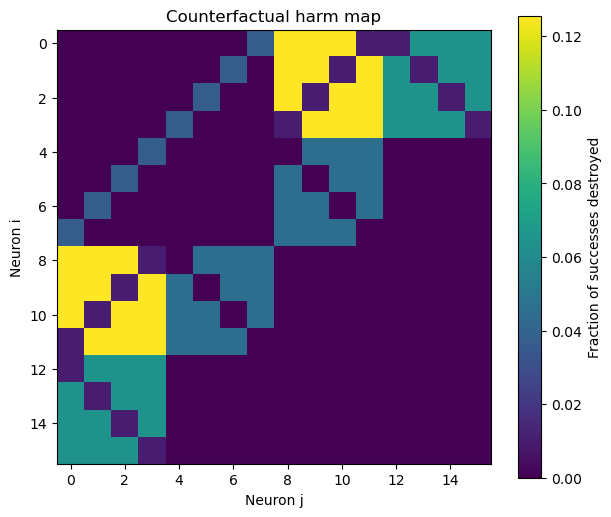

In [9]:
plt.figure(figsize=(7, 6))

plt.imshow(harm_map)

plt.colorbar(
    label="Fraction of successes destroyed"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Counterfactual harm map"
)

plt.show()

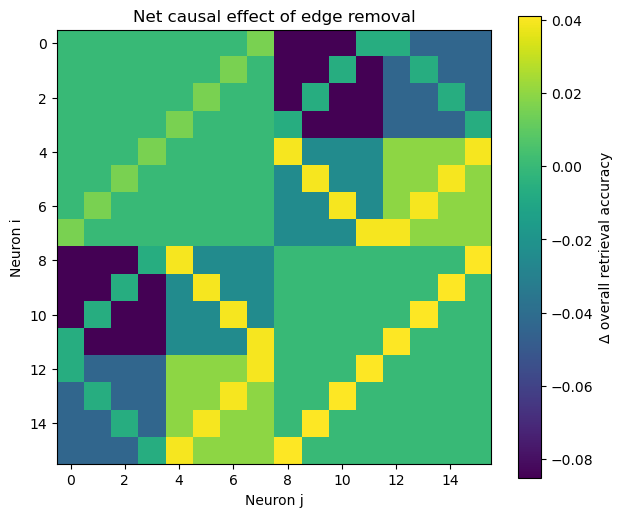

In [10]:
plt.figure(figsize=(7, 6))

plt.imshow(delta_acc_map)

plt.colorbar(
    label="Δ overall retrieval accuracy"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Net causal effect of edge removal"
)

plt.show()

In [11]:
edge_rows = []

for i in range(N):

    for j in range(i + 1, N):

        edge_rows.append({
            "i": i,
            "j": j,
            "weight": W[i, j].item(),
            "rescue": rescue_map[i, j].item(),
            "harm": harm_map[i, j].item(),
            "delta_accuracy":
                delta_acc_map[i, j].item()
        })

In [12]:
edge_rows_sorted = sorted(
    edge_rows,
    key=lambda x:
        x["delta_accuracy"],
    reverse=True
)

print("TOP ERROR-PROMOTING EDGES")

for row in edge_rows_sorted[:10]:

    print(
        f"({row['i']:2d},{row['j']:2d}) | "
        f"W={row['weight']:+.3f} | "
        f"rescue={row['rescue']:.3f} | "
        f"harm={row['harm']:.3f} | "
        f"ΔAcc={row['delta_accuracy']:+.4f}"
    )

TOP ERROR-PROMOTING EDGES
( 8,15) | W=-0.250 | rescue=0.128 | harm=0.000 | ΔAcc=+0.0412
( 9,14) | W=-0.250 | rescue=0.128 | harm=0.000 | ΔAcc=+0.0412
(10,13) | W=-0.250 | rescue=0.128 | harm=0.000 | ΔAcc=+0.0412
(11,12) | W=-0.250 | rescue=0.128 | harm=0.000 | ΔAcc=+0.0412
( 4, 8) | W=+0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396
( 4,15) | W=-0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396
( 5, 9) | W=+0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396
( 5,14) | W=-0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396
( 6,10) | W=+0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396
( 6,13) | W=-0.125 | rescue=0.123 | harm=0.000 | ΔAcc=+0.0396


In [13]:
print("\nTOP MEMORY-SUPPORTING EDGES")

for row in edge_rows_sorted[-10:]:

    print(
        f"({row['i']:2d},{row['j']:2d}) | "
        f"W={row['weight']:+.3f} | "
        f"rescue={row['rescue']:.3f} | "
        f"harm={row['harm']:.3f} | "
        f"ΔAcc={row['delta_accuracy']:+.4f}"
    )


TOP MEMORY-SUPPORTING EDGES
( 0,10) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 1, 8) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 1, 9) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 1,11) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 2, 8) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 2,10) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 2,11) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 3, 9) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 3,10) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852
( 3,11) | W=+0.125 | rescue=0.000 | harm=0.126 | ΔAcc=-0.0852


In [14]:
def rescued_failure_set(edge, W, failures, target):

    i, j = edge

    W_do = W.clone()
    W_do[i, j] = 0.0
    W_do[j, i] = 0.0

    rescued = set()

    for k, (_, x) in enumerate(failures):

        out = hopfield_retrieve_deterministic(
            x,
            W_do
        )

        if torch.equal(out, target):
            rescued.add(k)

    return rescued

In [15]:
# 10 edge error-promoting
top_edges = [
    (row["i"], row["j"])
    for row in edge_rows_sorted[:10]
]

rescue_sets = {
    e: rescued_failure_set(
        e,
        W,
        failures,
        target
    )
    for e in top_edges
}

E misuriamo l'overlap con l'indice di Jaccard:

In [17]:
jaccard = torch.zeros(
    len(top_edges),
    len(top_edges)
)

for a, e1 in enumerate(top_edges):

    for b, e2 in enumerate(top_edges):

        A = rescue_sets[e1]
        B = rescue_sets[e2]

        union = A | B

        if len(union) > 0:
            jaccard[a, b] = (
                len(A & B)
                / len(union)
            )

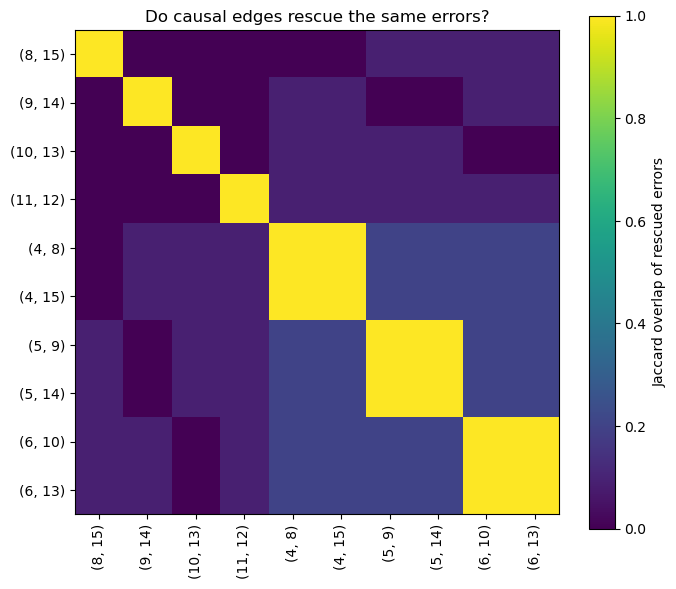

In [18]:
plt.figure(figsize=(7, 6))

plt.imshow(jaccard)

plt.colorbar(
    label="Jaccard overlap of rescued errors"
)

plt.xticks(
    range(len(top_edges)),
    [str(e) for e in top_edges],
    rotation=90
)

plt.yticks(
    range(len(top_edges)),
    [str(e) for e in top_edges]
)

plt.title(
    "Do causal edges rescue the same errors?"
)

plt.tight_layout()
plt.show()

Adesso definiamo:

$$ A_0= \text{accuracy originale}. $$

Per un edge \(e\):

$$ A_e= Acc(do(e=0)). $$

Per due edge:

$$ A_{ef} = Acc(do(e=0,f=0)). $$

La quantità interessante è:

$$ \boxed{ I(e,f) = A_{ef}-A_e-A_f+A_0 } $$

Questa è una differenza finita mista di secondo ordine.
Sta ad indicare:

### l'effetto combinato dei due interventi è diverso dalla somma dei loro effetti individuali?

In [19]:
def accuracy_after_edge_removal(
    edges,
    W,
    corruptions,
    target
):

    W_do = W.clone()

    for i, j in edges:
        W_do[i, j] = 0.0
        W_do[j, i] = 0.0

    correct = 0

    for _, x in corruptions:

        out = hopfield_retrieve_deterministic(
            x,
            W_do
        )

        if torch.equal(out, target):
            correct += 1

    return correct / len(corruptions)

In [21]:
# Baseline
A0 = len(successes) / len(corruptions)

In [22]:
single_acc = {}

for e in top_edges:

    single_acc[e] = (
        accuracy_after_edge_removal(
            [e],
            W,
            corruptions,
            target
        )
    )

In [23]:
interaction = torch.zeros(
    len(top_edges),
    len(top_edges)
)

for a, e1 in enumerate(top_edges):

    for b in range(a + 1, len(top_edges)):

        e2 = top_edges[b]

        A12 = accuracy_after_edge_removal(
            [e1, e2],
            W,
            corruptions,
            target
        )

        I12 = (
            A12
            - single_acc[e1]
            - single_acc[e2]
            + A0
        )

        interaction[a, b] = I12
        interaction[b, a] = I12

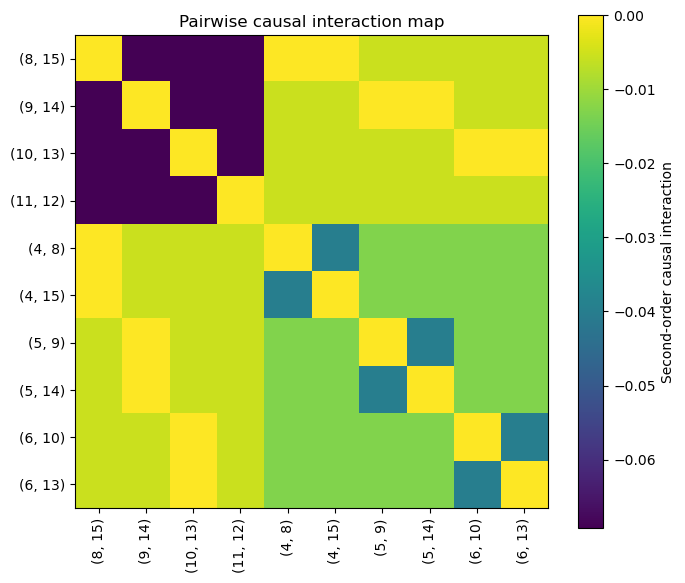

In [25]:
plt.figure(figsize=(7, 6))

plt.imshow(interaction)

plt.colorbar(
    label="Second-order causal interaction"
)

plt.xticks(
    range(len(top_edges)),
    [str(e) for e in top_edges],
    rotation=90
)

plt.yticks(
    range(len(top_edges)),
    [str(e) for e in top_edges]
)

plt.title(
    "Pairwise causal interaction map"
)

plt.tight_layout()
plt.show()

## Se pure_pair_rescuers è non vuoto, individua un errore che non può essere attribuito a un componente singolo, ma a una combinazione di componenti

In [26]:
failure_id = 0

indices, x_fail = failures[failure_id]

baseline_out = hopfield_retrieve_deterministic(
    x_fail,
    W
)

print("Flipped bits:", indices)

print("Target:")
print(target.numpy())

print("Baseline retrieval:")
print(baseline_out.numpy())

Flipped bits: (0, 4, 9, 12)
Target:
[ 1.  1.  1.  1. -1. -1. -1. -1.  1.  1.  1.  1. -1. -1. -1. -1.]
Baseline retrieval:
[ 1.  1.  1. -1.  1. -1. -1. -1.  1.  1.  1. -1.  1. -1. -1. -1.]


In [29]:
# ============================================================
# ANALISI DI UN SINGOLO ERRORE:
# single-edge rescuers + pure pair rescuers
# ============================================================

failure_id = 0

indices, x_fail = failures[failure_id]

baseline_out = hopfield_retrieve_deterministic(
    x_fail,
    W
)

print("Failure ID:", failure_id)
print("Flipped bits:", indices)
print("Target:")
print(target.numpy())

print("Baseline retrieval:")
print(baseline_out.numpy())


# ------------------------------------------------------------
# 1. Tutti gli edge non nulli
# ------------------------------------------------------------

all_edges = [
    (i, j)
    for i in range(N)
    for j in range(i + 1, N)
    if W[i, j].item() != 0.0
]

print("\nNon-zero edges:", len(all_edges))


# ------------------------------------------------------------
# 2. Edge singoli che correggono QUESTO errore
# ------------------------------------------------------------

single_rescuers = []

for e in all_edges:

    i, j = e

    W_do = W.clone()

    W_do[i, j] = 0.0
    W_do[j, i] = 0.0

    out = hopfield_retrieve_deterministic(
        x_fail,
        W_do
    )

    if torch.equal(out, target):
        single_rescuers.append(e)


print(
    "\nSingle-edge rescuers:",
    single_rescuers
)

print(
    "Number of single rescuers:",
    len(single_rescuers)
)

Failure ID: 0
Flipped bits: (0, 4, 9, 12)
Target:
[ 1.  1.  1.  1. -1. -1. -1. -1.  1.  1.  1.  1. -1. -1. -1. -1.]
Baseline retrieval:
[ 1.  1.  1. -1.  1. -1. -1. -1.  1.  1.  1. -1.  1. -1. -1. -1.]

Non-zero edges: 72

Single-edge rescuers: [(3, 4), (11, 12)]
Number of single rescuers: 2


In [30]:
# ------------------------------------------------------------
# 3. Pure pair rescuers
#
# La coppia corregge l'errore,
# ma nessuno dei due edge lo corregge da solo.
# ------------------------------------------------------------

single_rescuers_set = set(single_rescuers)

pure_pair_rescuers = []

for a in range(len(all_edges)):

    for b in range(a + 1, len(all_edges)):

        e1 = all_edges[a]
        e2 = all_edges[b]

        # Vogliamo solo interazioni realmente "di coppia"
        if (
            e1 in single_rescuers_set
            or e2 in single_rescuers_set
        ):
            continue

        W_do = W.clone()

        for i, j in [e1, e2]:

            W_do[i, j] = 0.0
            W_do[j, i] = 0.0

        out = hopfield_retrieve_deterministic(
            x_fail,
            W_do
        )

        if torch.equal(out, target):

            pure_pair_rescuers.append(
                (e1, e2)
            )


print(
    "\nFirst 20 pure pair rescuers:"
)

for pair in pure_pair_rescuers[:20]:
    print(pair)

print(
    "\nNumber of pure pair rescuers:",
    len(pure_pair_rescuers)
)


First 20 pure pair rescuers:
((0, 11), (3, 11))
((0, 11), (4, 11))
((0, 11), (7, 11))
((3, 8), (3, 9))
((3, 8), (3, 11))
((3, 8), (3, 12))
((3, 8), (3, 15))
((3, 9), (3, 12))
((3, 9), (3, 15))
((3, 11), (3, 12))
((3, 11), (3, 15))
((3, 11), (4, 11))
((3, 11), (7, 11))
((3, 12), (3, 15))
((4, 11), (7, 11))

Number of pure pair rescuers: 15


In [31]:
def trace_retrieval(
    initial_state,
    W,
    target,
    max_sweeps=10
):

    s = initial_state.clone()

    trace = []

    for sweep in range(max_sweeps):

        changed = False

        for i in range(len(s)):

            old_value = s[i].item()

            field = torch.dot(
                W[i],
                s
            ).item()

            target_margin = (
                target[i].item()
                * field
            )

            new_value = (
                1.0
                if field >= 0
                else -1.0
            )

            trace.append({
                "sweep": sweep,
                "neuron": i,
                "old": old_value,
                "field": field,
                "target": target[i].item(),
                "margin": target_margin,
                "new": new_value
            })

            if new_value != old_value:

                s[i] = new_value
                changed = True

        if not changed:
            break

    return s, trace

In [32]:
out_base, trace_base = trace_retrieval(
    x_fail,
    W,
    target
)

In [33]:
W_single = W.clone()

W_single[3,4] = 0.0
W_single[4,3] = 0.0

out_single, trace_single = trace_retrieval(
    x_fail,
    W_single,
    target
)

In [34]:
W_pair = W.clone()

for i, j in [
    (3,8),
    (3,9)
]:

    W_pair[i,j] = 0.0
    W_pair[j,i] = 0.0

out_pair, trace_pair = trace_retrieval(
    x_fail,
    W_pair,
    target
)

In [35]:
critical = {3,4,11,12}

print(
    "sweep | neuron | baseline margin "
    "| single margin | pair margin"
)

for k in range(
    min(
        len(trace_base),
        len(trace_single),
        len(trace_pair)
    )
):

    b = trace_base[k]
    s = trace_single[k]
    p = trace_pair[k]

    if b["neuron"] in critical:

        print(
            f'{b["sweep"]:2d} | '
            f'{b["neuron"]:2d} | '
            f'{b["margin"]:+.4f} | '
            f'{s["margin"]:+.4f} | '
            f'{p["margin"]:+.4f}'
        )

sweep | neuron | baseline margin | single margin | pair margin
 0 |  3 | -0.2500 | +0.0000 | +0.0000
 0 |  4 | -0.2500 | -0.0000 | +0.2500
 0 | 11 | -0.2500 | +0.0000 | +0.2500
 0 | 12 | -0.2500 | +0.5000 | +0.7500
 1 |  3 | -0.2500 | +0.5000 | +0.7500
 1 |  4 | -0.2500 | +0.5000 | +0.7500
 1 | 11 | -0.2500 | +0.7500 | +0.7500
 1 | 12 | -0.2500 | +0.7500 | +0.7500


In [36]:
def retrieve_with_overlap_trace(
    initial_state,
    W,
    patterns,
    max_sweeps=10
):
    s = initial_state.clone()

    states = [s.clone()]
    overlaps = []

    def get_overlaps(state):
        return torch.tensor([
            torch.dot(p, state).item() / len(state)
            for p in patterns
        ])

    overlaps.append(
        get_overlaps(s)
    )

    for sweep in range(max_sweeps):

        changed = False

        for i in range(len(s)):

            field = torch.dot(
                W[i],
                s
            )

            new_value = (
                1.0
                if field >= 0
                else -1.0
            )

            if new_value != s[i]:
                s[i] = new_value
                changed = True

        states.append(
            s.clone()
        )

        overlaps.append(
            get_overlaps(s)
        )

        if not changed:
            break

    return (
        s,
        torch.stack(overlaps),
        states
    )

In [37]:
# BASELINE
out_base, ov_base, states_base = (
    retrieve_with_overlap_trace(
        x_fail,
        W,
        patterns
    )
)


# SINGLE RESCUE: (3,4)
W_single = W.clone()

W_single[3,4] = 0
W_single[4,3] = 0

out_single, ov_single, states_single = (
    retrieve_with_overlap_trace(
        x_fail,
        W_single,
        patterns
    )
)


# PURE SECOND-ORDER RESCUE:
# (3,8) e (3,9)
W_pair = W.clone()

for i, j in [
    (3,8),
    (3,9)
]:
    W_pair[i,j] = 0
    W_pair[j,i] = 0

out_pair, ov_pair, states_pair = (
    retrieve_with_overlap_trace(
        x_fail,
        W_pair,
        patterns
    )
)

In [38]:
def print_overlaps(name, ov):

    print(f"\n{name}")

    for t in range(len(ov)):

        values = " | ".join(
            [
                f"m{mu}={ov[t,mu]:+.3f}"
                for mu in range(
                    ov.shape[1]
                )
            ]
        )

        print(
            f"t={t} | {values}"
        )


print_overlaps(
    "BASELINE",
    ov_base
)

print_overlaps(
    "SINGLE (3,4)",
    ov_single
)

print_overlaps(
    "PAIR (3,8)+(3,9)",
    ov_pair
)


BASELINE
t=0 | m0=+0.500 | m1=+0.250 | m2=+0.000 | m3=-0.250
t=1 | m0=+0.500 | m1=+0.500 | m2=+0.500 | m3=+0.000
t=2 | m0=+0.500 | m1=+0.500 | m2=+0.500 | m3=+0.000

SINGLE (3,4)
t=0 | m0=+0.500 | m1=+0.250 | m2=+0.000 | m3=-0.250
t=1 | m0=+0.875 | m1=+0.125 | m2=+0.125 | m3=-0.125
t=2 | m0=+1.000 | m1=+0.000 | m2=+0.000 | m3=+0.000
t=3 | m0=+1.000 | m1=+0.000 | m2=+0.000 | m3=+0.000

PAIR (3,8)+(3,9)
t=0 | m0=+0.500 | m1=+0.250 | m2=+0.000 | m3=-0.250
t=1 | m0=+1.000 | m1=+0.000 | m2=+0.000 | m3=+0.000
t=2 | m0=+1.000 | m1=+0.000 | m2=+0.000 | m3=+0.000


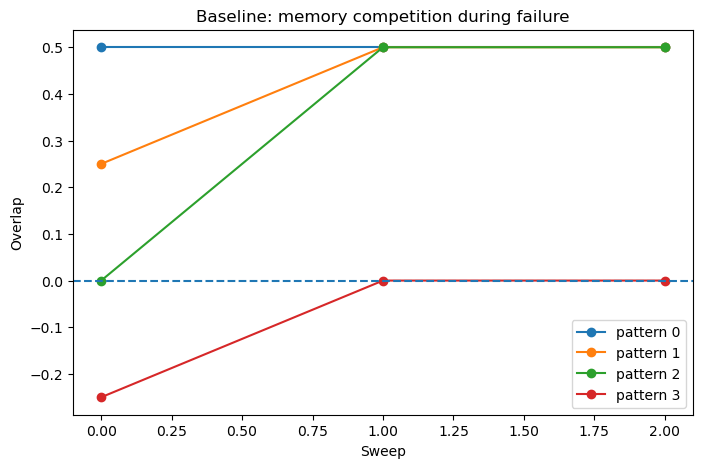

In [39]:
plt.figure(figsize=(8,5))

for mu in range(len(patterns)):

    plt.plot(
        range(len(ov_base)),
        ov_base[:,mu],
        marker="o",
        label=f"pattern {mu}"
    )

plt.xlabel("Sweep")
plt.ylabel("Overlap")

plt.title(
    "Baseline: memory competition during failure"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.legend()
plt.show()